# Soul mates with Bayes, on the POLYMOD survey

POLYMOD asked 7290 people in 8 European countries in 2005 and 2006 to write down everyone they met on one day (Mossong et al. 2008, Zenodo record 3874557, licence CC BY-NC 4.0). A contact counts when two people touch skin to skin, or talk face to face for at least three words. For each contact, people said how often they usually meet that person, and a contact marked "first time" is a new person. So this notebook counts new people you meet and talk to, not people you only glance at. Run `uv run python scripts/download_polymod.py` and `uv run python scripts/download_wpp.py` once before this notebook.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from soulmates.model import age_band, build_model, p_find
from soulmates.polymod import load_polymod

df = load_polymod("../data/raw")
df.head()

no part_age: 65 of 7290 rows (0.9%)
no dayofweek: 136 of 7290 rows (1.9%)
no frequency_multi: 1407 of 97904 rows (1.4%)


,age,new_contacts,weekend,country
0,8,3,False,IT
1,6,0,False,IT
2,0,2,False,IT
3,1,0,False,IT
4,2,0,False,IT


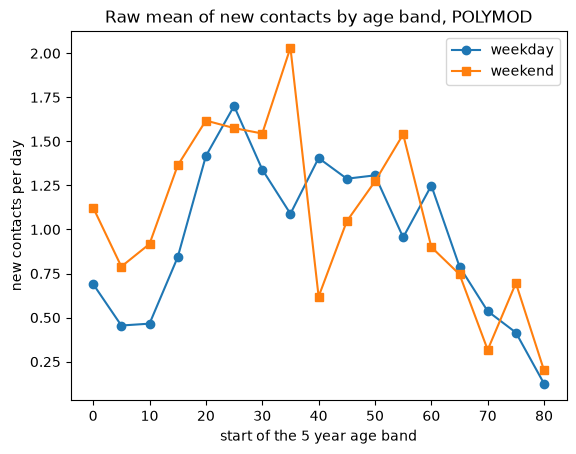

In [2]:
raw = df.groupby([age_band(df["age"]), "weekend"])["new_contacts"].mean().unstack()
fig, ax = plt.subplots()
ax.plot(raw.index * 5, raw[False], "o-", label="weekday")
ax.plot(raw.index * 5, raw[True], "s-", label="weekend")
ax.set(xlabel="start of the 5 year age band", ylabel="new contacts per day", title="Raw mean of new contacts by age band, POLYMOD")
ax.legend();

## Fit

The model is the one from the simulated notebook, plus a weekend term `beta_weekend`. A weekend day has exp(beta_weekend) times the new contacts of a weekday.

In [3]:
# The speaker's guess: "I am 90% sure that p_recog lies between 0.1 and 0.6"
RECOG_BOUNDS = (0.1, 0.6)
RECOG_MASS = 0.9

model = build_model(df, recog_bounds=RECOG_BOUNDS, recog_mass=RECOG_MASS)
with model:
    idata = pm.sample(random_seed=2)
az.summary(idata, var_names=["mu_pop", "sigma_band", "alpha", "beta_weekend", "lifetime_new", "p_recog"])

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_pop, sigma_band, z, beta_weekend, alpha, p_recog]


/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 64 seconds.


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_pop,-0.117,0.125,-0.32,0.081,812,996,1.00,0.0044,0.0029
sigma_band,0.457,0.105,0.31,0.64,857,1345,1.00,0.0036,0.0022
alpha,0.2328,0.0072,0.22,0.24,4771,2867,1.00,0.0001,0.00012
beta_weekend,0.217,0.066,0.11,0.32,3772,2725,1.00,0.0011,0.0011
lifetime_new,2.07e+04,7.88e+02,19000,22000,3969,3342,1.00,13,10
p_recog,0.356,0.153,0.13,0.62,4295,2417,1.00,0.0023,0.0024


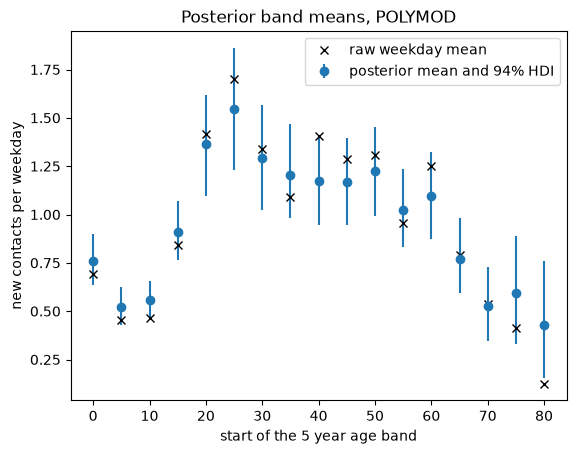

In [4]:
hdi = az.hdi(idata, var_names=["band_mean"], prob=0.94)["band_mean"].values
mean = idata.posterior["band_mean"].mean(("chain", "draw")).values
ages = np.arange(17) * 5
fig, ax = plt.subplots()
ax.errorbar(ages, mean, yerr=[mean - hdi[:, 0], hdi[:, 1] - mean], fmt="o", label="posterior mean and 94% HDI")
ax.plot(raw.index * 5, raw[False], "kx", label="raw weekday mean")
ax.set(xlabel="start of the 5 year age band", ylabel="new contacts per weekday", title="Posterior band means, POLYMOD")
ax.legend();

weekend multiplier 1.24, 94% interval 1.10 to 1.41
lifetime new contacts 20665, 94% interval 19212 to 22180


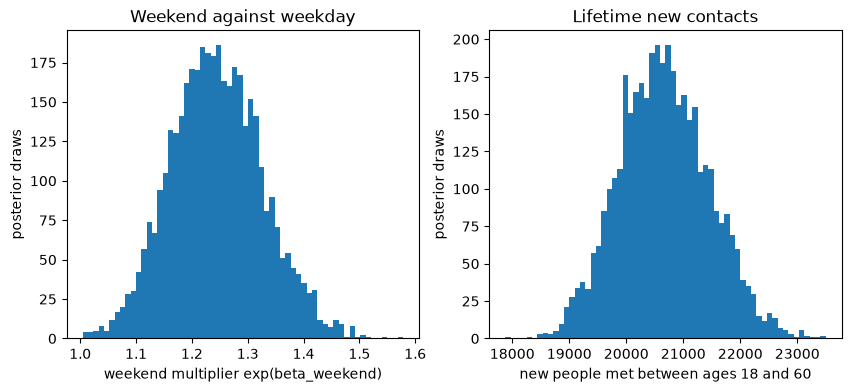

In [5]:
multiplier = np.exp(idata.posterior["beta_weekend"].values.ravel())
lifetime = idata.posterior["lifetime_new"].values.ravel()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.hist(multiplier, bins=60)
ax1.set(xlabel="weekend multiplier exp(beta_weekend)", ylabel="posterior draws", title="Weekend against weekday")
ax2.hist(lifetime, bins=60)
ax2.set(xlabel="new people met between ages 18 and 60", ylabel="posterior draws", title="Lifetime new contacts")
print(f"weekend multiplier {multiplier.mean():.2f}, 94% interval {np.percentile(multiplier, 3):.2f} to {np.percentile(multiplier, 97):.2f}")
print(f"lifetime new contacts {lifetime.mean():.0f}, 94% interval {np.percentile(lifetime, 3):.0f} to {np.percentile(lifetime, 97):.0f}")

## The guess behind p_recog

p_recog is the chance that, when you meet your soul mate and talk for the first time, you both realize it then. No data informs it. The guess "I am 90% sure it lies between 0.1 and 0.6" becomes a Beta prior through PreliZ `maxent`, which picks the flattest Beta curve that puts 90% between the two bounds. Mossong et al. report that about three quarters of first time contacts lasted less than 15 minutes, which is why the guess sits low. The posterior of p_recog equals its prior, so the draws below show the prior.

p_recog mean 0.356, share between the bounds 0.904

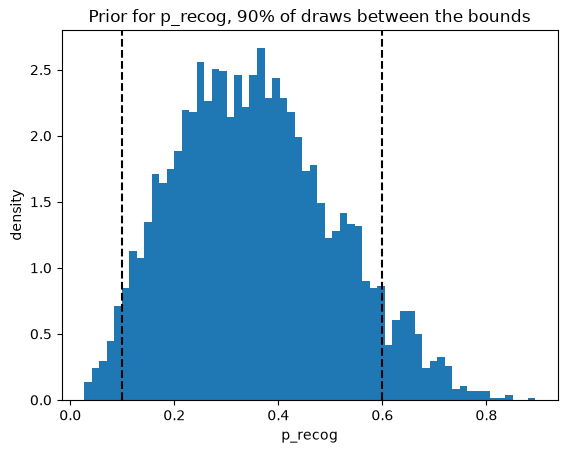

In [6]:
p_recog = idata.posterior["p_recog"].values.ravel()
inside = ((p_recog > RECOG_BOUNDS[0]) & (p_recog < RECOG_BOUNDS[1])).mean()
fig, ax = plt.subplots()
ax.hist(p_recog, bins=60, density=True)
for bound in RECOG_BOUNDS:
    ax.axvline(bound, color="k", linestyle="--")
ax.set(xlabel="p_recog", ylabel="density", title=f"Prior for p_recog, {inside:.0%} of draws between the bounds")
print(f"p_recog mean {p_recog.mean():.3f}, share between the bounds {inside:.3f}")

## The chance of finding your soul mate

P_find = 1 − (1 − p_recog / M) ^ lifetime_new. M is everyone alive in 2023 aged 25 to 35, from the UN World Population Prospects 2024 (licence CC BY 3.0 IGO). p_recog is the only guessed number left, and it drives the spread of the result.

world: M = 1,328,956,521, P_find mean 5.53e-06 (1 in 180,740), 94% interval 1.60e-06 to 1.04e-05
8 POLYMOD countries: M = 39,411,641, P_find mean 1.87e-04 (1 in 5,361), 94% interval 5.39e-05 to 3.49e-04


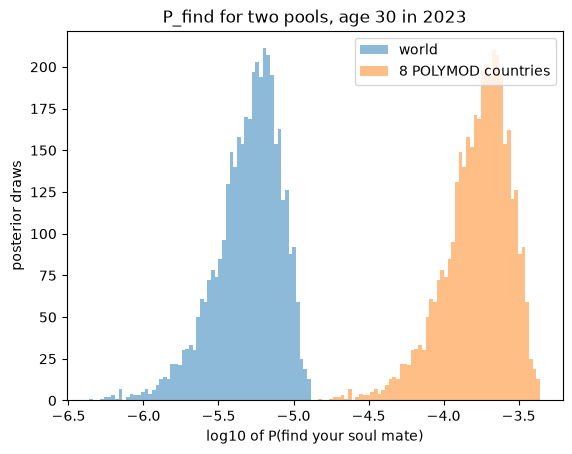

In [7]:
import pandas as pd
from soulmates.wpp import POLYMOD_COUNTRIES, pool_size

wpp = pd.read_csv("../data/wpp_pool.csv")  # written by scripts/download_wpp.py
pools = {"world": pool_size(wpp), "8 POLYMOD countries": pool_size(wpp, locations=POLYMOD_COUNTRIES)}
fig, ax = plt.subplots()
for label, m in pools.items():
    pf = p_find(idata, m).values.ravel()
    print(f"{label}: M = {m:,.0f}, P_find mean {pf.mean():.2e} (1 in {1 / pf.mean():,.0f}), "
          f"94% interval {np.percentile(pf, 3):.2e} to {np.percentile(pf, 97):.2e}")
    ax.hist(np.log10(pf), bins=60, alpha=0.5, label=label)
ax.set(xlabel="log10 of P(find your soul mate)", ylabel="posterior draws", title="P_find for two pools, age 30 in 2023")
ax.legend();

## How much does Germany matter?

Diaries in Belgium, Germany, Finland and the Netherlands asked people to give an estimate of their professional contacts instead of listing each one (Mossong et al. 2008, Discussion). Those contacts have no frequency, so none of them can count as first time. Germany records far fewer new contacts than the other countries, and it is the largest sample. This cell fits the model again without Germany.

In [8]:
no_de = df[df["country"] != "DE"]
with build_model(no_de, recog_bounds=RECOG_BOUNDS, recog_mass=RECOG_MASS):
    idata_no_de = pm.sample(random_seed=2)
for label, d in [("all 8 countries", idata), ("without Germany", idata_no_de)]:
    life = d.posterior["lifetime_new"].values.ravel()
    pf = p_find(d, pools["world"]).values.ravel()
    print(f"{label}: lifetime new contacts {life.mean():.0f} "
          f"({np.percentile(life, 3):.0f} to {np.percentile(life, 97):.0f}), "
          f"world P_find mean {pf.mean():.2e}, 1 in {1 / pf.mean():,.0f}")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_pop, sigma_band, z, beta_weekend, alpha, p_recog]


/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 46 seconds.


all 8 countries: lifetime new contacts 20665 (19212 to 22180), world P_find mean 5.53e-06, 1 in 180,740
without Germany: lifetime new contacts 24129 (22455 to 25920), world P_find mean 6.41e-06, 1 in 155,990


## Known limits

1. Four countries asked for an estimate of professional contacts instead of a list, and Germany records far fewer new contacts than the rest. The cell above shows how much that moves the result.
2. The recovery test runs at alpha = 2, while this data sits near alpha = 0.23. The model is not tested at that level of spread.
3. All 8 countries are pooled into one sample.
4. The pool counts everyone and ignores gender and orientation.
5. M is a fixed number from the WPP estimates, without uncertainty.
6. Strangers you only glance at are not counted. The premise is people you meet and talk to.